# 04 · Entrenar nuestra primera red neuronal

Vamos a enseñar a una red pequeña a distinguir los tipos de prenda conservados. Usaremos los datos preparados en 02 y las referencias de 03 para entender qué aprende y dónde falla.

Primero veremos cómo entran las imágenes en la red. Después entrenaremos, leeremos los resultados y comprobaremos si añadir dropout ayuda. La prioridad es explicar el proceso, no buscar la mayor puntuación.

> **Ejecución guardada y validada · 25/11/2026.** Las 18 celdas están ejecutadas sin errores. Experimento `143ad91452347fef`, con 25 clases y seis ajustes sobre `20261125T152902-c912cdcc`. Checkpoints, predicciones y manifiesto comprobados; ninguna predicción de test. Tras terminar se devuelve ENTRENAR_SI_FALTA a False para reutilizar resultados, conservando las salidas reales.


> **Pendiente de validar con el filtro automático de 02.** Los resultados de entrenamiento que siguen guardados corresponden al conjunto anterior al filtro de zoom. La presentación se ha actualizado; las figuras pendientes deben redibujarse. Las ejecuciones anteriores completas están conservadas en Git.

## 1. Qué queremos comprobar

Entrenaremos una **Dense o MLP**: una red de capas donde cada neurona combina todos los valores que recibe.

Compararemos la misma red **sin dropout y con dropout 0,30**. Repetiremos cada opción con tres semillas para comprobar si el resultado depende mucho de la aleatoriedad.

También la compararemos con los modelos sencillos de 03. La comparación con una CNN llegará en 05; todavía no podemos concluir cuál funciona mejor.

**Palabras que usaremos:** una época es una pasada por train; un batch es un grupo de imágenes; una semilla permite repetir la aleatoriedad; un checkpoint guarda los pesos de una época concreta.

## 2. Preparar el entorno

Selecciona el Python de `.venv`, el mismo entorno que contiene PyTorch. Usamos CPU y cuatro hilos.

La configuración está en `config/dense_baseline_v1.json`. Empezamos con Adam para actualizar los pesos y entropía cruzada para medir el error. No añadimos aumentos ni pesos de clase: así podremos estudiar sus efectos por separado más adelante.

In [1]:
from pathlib import Path
import sys, json, inspect, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display, Markdown, Code
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/data/local_dataset.py').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.models.dense import DenseClassifier, parameter_count
from src.training.dense_experiment import (
    load_context, prepare_arrays, normalized_tensors, run_or_load,
    model_from_config, train_epoch, SelectionState, grouped_intervals, sha256,
)
from src.visualization.style import apply_style, format_number as number, format_percent as percent
from src.visualization.tables import display_es
from src.visualization.dense import (
    input_figure, curves_figure, dropout_figure, confusion_figure,
    per_class_figure, errors_figure, weight_figure, activation_figure,
)
apply_style()
context = load_context(ROOT)
eda_provenance = ROOT/'results/metrics/03_eda/dataset_provenance.json'
if not eda_provenance.exists() or json.loads(eda_provenance.read_text())['manifest_sha256'] != context['manifest_sha256']:
    raise ValueError('Ejecuta primero 03 con la publicación vigente de 02: las referencias deben usar el mismo train.')
config = context['config']
ENTRENAR_SI_FALTA = False
from src.training.saved_experiments import load_saved_experiment
cached_experiment = None
if not ENTRENAR_SI_FALTA:
    # Comprobar antes de preparar arrays o normalizar: no iniciar trabajo pesado por sorpresa.
    cached_experiment = load_saved_experiment(context)
torch.set_num_threads(config['training']['threads'])
torch.use_deterministic_algorithms(True)
display_es(pd.DataFrame({
    'Decisión': ['PyTorch', 'Dispositivo', 'Hilos CPU', 'Semillas', 'Batch', 'Máximo épocas', 'Paciencia', 'Learning rate'],
    'Valor': [torch.__version__, 'CPU', 4, '42, 123 y 2026', 32, 30, 5, '0,001'],
}))

Experimento 143ad91452347fef cargado; no se entrena ninguna red.


Decisión,Valor
PyTorch,2.2.2
Dispositivo,CPU
Hilos CPU,4
Semillas,"42, 123 y 2026"
Batch,32
Máximo épocas,30
Paciencia,5
Learning rate,"0,001"


## 3. Comprobar los datos que vamos a usar

Leemos la publicación de 02. Conservamos sus clases con ejemplos tras los filtros, sus cantidades desiguales y la separación por productos.

**Train** sirve para aprender. **Validation** sirve para elegir la época y analizar los resultados. **Test** queda reservado: aquí comprobamos sus registros, pero no abrimos sus fotos.

La tabla siguiente muestra la publicación concreta y cuántas imágenes contiene cada conjunto. Si 02 aplica el filtro de zoom, aquí debemos recibir los tres conjuntos ya filtrados; no hacemos otra selección dentro de la red.

In [2]:
rows = context['rows']
names = context['names']
display(Markdown(f"**Publicación:** `{context['run'].name}`. Manifiesto verificado por SHA-256."))
split_table = pd.DataFrame({
    'Partición': ['train', 'validation', 'test'],
    'Imágenes': [context['split_counts'][s] for s in ['train', 'validation', 'test']],
    'Uso aquí': ['Aprender pesos y normalización', 'Parada, checkpoint y análisis', 'Reservado; no se abren fotografías'],
})
display_es(split_table)
count_rows = pd.concat(rows.values(), ignore_index=True)
display_es(pd.crosstab(count_rows.label, count_rows.split).reindex(names))
missing_validation = sorted(set(names) - set(rows['validation'].label))
if missing_validation:
    display(Markdown(f"**Clases sin fotos en validation:** {', '.join(missing_validation)}. La red las aprende en train, pero no se pueden evaluar. Macro-F1 promedia las {len(names)} clases, como en 03, así que estas cuentan con F1 = 0."))
assert set(rows['train'].group_id).isdisjoint(rows['validation'].group_id)
print('Controles superados: grupos, productos, píxeles, etiquetas y hashes del manifiesto.')

**Publicación:** `20261125T152902-c912cdcc`. Manifiesto verificado por SHA-256.

Partición,Imágenes,Uso aquí
train,33.618,Aprender pesos y normalización
validation,7.515,"Parada, checkpoint y análisis"
test,7.243,Reservado; no se abren fotografías


Clase,train,validation
Blazer,679,142
Blouse,2.294,528
Bodysuit,158,36
Cardigan,642,133
Coat,288,58
Costumes,1,0
Dress,5.311,1.156
Dungarees,71,19
Garment Set,29,7
Hoodie,865,228


**Clases sin fotos en validation:** Costumes. La red las aprende en train, pero no se pueden evaluar. Macro-F1 promedia las 25 clases, como en 03, así que estas cuentan con F1 = 0.

Controles superados: grupos, productos, píxeles, etiquetas y hashes del manifiesto.


## 4. Convertir las imágenes en entradas de la red

02 guarda copias de **224 × 224**. Esta red recibe una copia más pequeña de **64 × 64**, con los tres canales de color: son **12.288 números por imagen**.

Reducimos el coste de la Dense sin cambiar los productos ni las particiones. La comparación visual muestra la misma imagen en los dos tamaños. Perdemos detalle al reducirla; es una limitación del experimento.

Comprobamos los archivos y guardamos arrays en una caché local. Eso evita abrir los JPEG en cada época y permite trabajar por lotes sin cargar todos los datos en RAM.

In [3]:
# Solo presentación: esta celda no entrena ni carga datos nuevos.
import importlib
import src.visualization.dense as dense_display
importlib.reload(dense_display)
from src.visualization.dense import (
    show_compact, show_code, run_with_progress, input_figure, curves_figure, dropout_figure,
    confusion_figure, per_class_figure, errors_figure, weight_figure, activation_figure,
)

train: 4.000 imágenes verificadas


train: 8.000 imágenes verificadas


train: 12.000 imágenes verificadas


train: 16.000 imágenes verificadas


train: 20.000 imágenes verificadas


train: 24.000 imágenes verificadas


train: 28.000 imágenes verificadas


train: 32.000 imágenes verificadas


validation: 4.000 imágenes verificadas


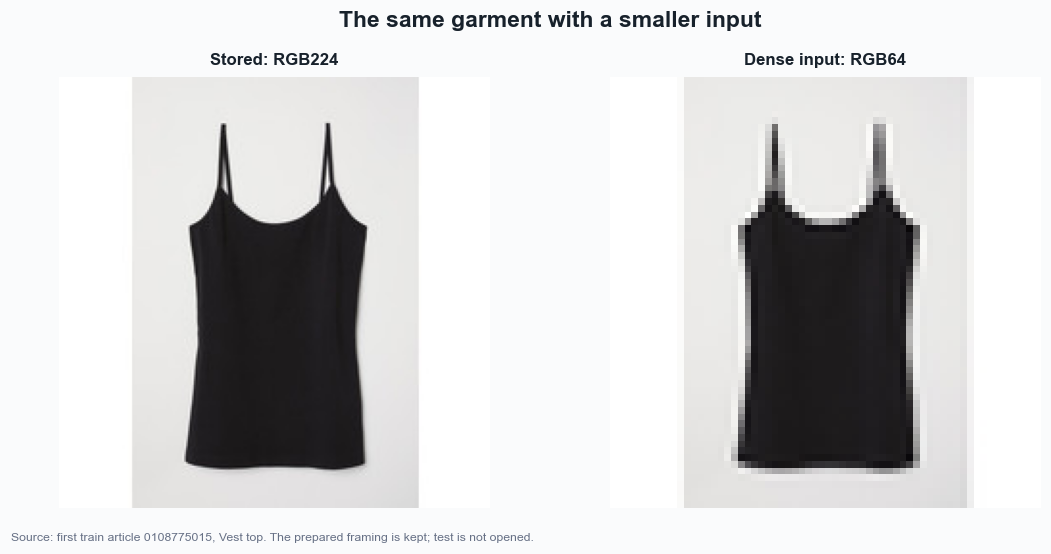

Preparación/verificación en esta ejecución: **47,1 s**. La duración cambia si existe caché.

In [4]:
prepared_at = time.perf_counter()
raw, normalization = prepare_arrays(context)
preparation_seconds = time.perf_counter() - prepared_at
show_compact(input_figure(context, raw), width=600)
display(Markdown(f"Preparación/verificación en esta ejecución: **{number(preparation_seconds, 1)} s**. La duración cambia si existe caché."))

### Poner los canales de color en una escala comparable

Primero dividimos los píxeles entre 255 para obtener valores entre 0 y 1. Después aplicamos, por canal:

`valor normalizado = (valor − media de train) / desviación de train`

La media y la desviación se calculan **solo con train y a 64 × 64**. Validation usa esos mismos números. Tras normalizar, esperamos una media cercana a cero y una desviación cercana a uno en train; las tablas lo comprueban.

In [5]:
tensors = normalized_tensors(raw, normalization)
normalization_table = pd.DataFrame({
    'Canal': ['R', 'G', 'B'], 'Media train RGB64': normalization['mean'],
    'Desviación train RGB64': normalization['std'],
})
display_es(normalization_table)
channel_checks = []
for channel, label in enumerate(['R', 'G', 'B']):
    values = tensors['train'][:, channel]
    channel_checks.append({'Canal': label, 'Media normalizada train': float(values.mean()),
                           'Desviación normalizada train': float(values.std(unbiased=False))})
display_es(pd.DataFrame(channel_checks))
assert max(abs(r['Media normalizada train']) for r in channel_checks) < 1e-4
assert max(abs(r['Desviación normalizada train']-1) for r in channel_checks) < 1e-4
assert set(tensors) == {'train', 'validation'}
display(Markdown(f"**Forma de un batch:** `{tuple(tensors['train'][:32].shape)}` = imágenes × canales × alto × ancho."))

Canal,Media train RGB64,Desviación train RGB64
R,"0,825","0,266"
G,"0,810","0,278"
B,"0,807","0,276"


Canal,Media normalizada train,Desviación normalizada train
R,"9,08e-08",1
G,"-5,36e-08","1,000"
B,"-3,72e-08","1,000"


**Forma de un batch:** `(32, 3, 64, 64)` = imágenes × canales × alto × ancho.

## 5. Entender la red

La secuencia es **Flatten → Dense(80) → ReLU → Dense(32) → ReLU → Dense(número de clases conservadas)**.

- **Flatten** coloca los píxeles en una lista de números.
- Las capas **Dense** combinan esos números mediante pesos que se aprenden.
- **ReLU** deja pasar los valores positivos y convierte los negativos en cero. Permite aprender relaciones no lineales.
- La última capa devuelve una puntuación por clase conservada: una por tipo de prenda.

Fijamos 80 y 32 neuronas para tener aproximadamente un millón de parámetros. No hemos buscado sus tamaños probando muchas alternativas. La tabla muestra cómo cambia la forma de los datos en cada capa. Puedes desplegar el código si quieres seguir la implementación.

In [6]:
torch.manual_seed(42)
example_model = model_from_config(config, dropout=0.0)
show_code(inspect.getsource(DenseClassifier), 'Ver el código de la red')
architecture = []
shape = (32, 3, 64, 64)
for name, module in example_model.network.named_children():
    with torch.no_grad():
        output = module(torch.zeros(shape))
    architecture.append({'Capa': type(module).__name__, 'Entrada': str(shape),
                         'Salida': str(tuple(output.shape)), 'Parámetros': sum(p.numel() for p in module.parameters())})
    shape = tuple(output.shape)
display_es(pd.DataFrame(architecture))
parameters = parameter_count(example_model)
widths=[3*config['architecture']['image_size']**2,*config['architecture']['hidden_dims'],len(names)]
expected_parameters=sum((inputs+1)*outputs for inputs,outputs in zip(widths[:-1],widths[1:]))
assert parameters == expected_parameters
assert abs(parameters/1_000_000-1) <= .10
display(Markdown(f"**Total: {number(parameters)} parámetros entrenables.** La primera Dense concentra la mayor parte del presupuesto."))

Capa,Entrada,Salida,Parámetros
Flatten,"(32, 3, 64, 64)","(32, 12288)",0
Linear,"(32, 12288)","(32, 80)",983.120
ReLU,"(32, 80)","(32, 80)",0
Dropout,"(32, 80)","(32, 80)",0
Linear,"(32, 80)","(32, 32)",2.592
ReLU,"(32, 32)","(32, 32)",0
Dropout,"(32, 32)","(32, 32)",0
Linear,"(32, 32)","(32, 25)",825


**Total: 986.537 parámetros entrenables.** La primera Dense concentra la mayor parte del presupuesto.

### Ver una predicción antes de entrenar

Al principio los pesos son aleatorios. Las puntuaciones de salida se llaman **logits**. Softmax las convierte en números entre 0 y 1 que suman uno, pero todavía no esperamos predicciones útiles.

La **entropía cruzada** penaliza que la red asigne poca probabilidad a la clase correcta. Mostramos una imagen de train y comprobamos que el cálculo manual de esta pérdida coincide con PyTorch.

In [7]:
image = tensors['train'][:1]
target = torch.tensor([int(rows['train'].iloc[0].label_id)])
example_model.eval()
with torch.no_grad():
    logits = example_model(image)
    probabilities = logits.softmax(1)
    loss = nn.CrossEntropyLoss()(logits, target)
    manual_loss = -logits.log_softmax(1)[0, target.item()]
torch.testing.assert_close(loss, manual_loss)
display_es(pd.DataFrame({'Clase': names, 'Logit sin entrenar': logits[0].numpy(),
                         'Probabilidad sin entrenar': probabilities[0].numpy()}))
display(Markdown(f"Clase real: **{names[target.item()]}**. Pérdida del ejemplo: **{number(float(loss), 4)}**. Referencia uniforme: **{number(float(np.log(len(names))), 4)}**."))

Clase,Logit sin entrenar,Probabilidad sin entrenar
Blazer,"0,365","0,055"
Blouse,"0,248","0,049"
Bodysuit,"-0,089","0,035"
Cardigan,"0,607","0,070"
Coat,"-0,390","0,026"
Costumes,"-0,258","0,030"
Dress,"-0,018","0,038"
Dungarees,"-0,371","0,026"
Garment Set,"-0,139","0,033"
Hoodie,"0,258","0,050"


Clase real: **Vest top**. Pérdida del ejemplo: **3,4287**. Referencia uniforme: **3,2189**.

## 6. Cómo aprende y cuándo dejamos de entrenar

En cada batch la red hace una predicción, calcula el error, obtiene los gradientes y actualiza los pesos con Adam. Una época repite ese proceso para todo train.

Al terminar cada época evaluamos train y validation. Usamos dos reglas distintas:

- **Guardar:** conservamos la época con mejor macro-F1 de validation; si hay empate, la primera.
- **Parar:** terminamos si la pérdida de validation no mejora durante cinco épocas seguidas, o al llegar a 30 épocas.

Por eso la última época entrenada puede ser distinta de la época guardada. El código de estas reglas se puede desplegar debajo.

In [8]:
show_code(inspect.getsource(train_epoch), 'Ver cómo se entrena una época')
show_code(inspect.getsource(SelectionState), 'Ver las reglas para guardar y parar')

## 7. Medir el coste y entrenar las seis ejecuciones

Primero medimos una época piloto; sus pesos se descartan. Esta medida permite estimar el coste antes de entrenar todas las variantes.

Después entrenamos la red sin dropout y con dropout 0,30, usando las semillas **42, 123 y 2026** en ambos casos. Con `ENTRENAR_SI_FALTA=False` se cargan resultados compatibles; si faltan, el cuaderno se detiene. Solo al activar expresamente la bandera se permite crear un experimento. Cambiar texto, figuras o métricas de análisis no requiere entrenar.

Las tablas separan las puntuaciones de los tiempos y las épocas. **Macro-F1** da el mismo peso a cada clase. **Accuracy** cuenta la proporción total de aciertos y puede favorecer las clases grandes. Ambas aparecen en escala 0–1; una accuracy de 0,60 equivale al 60 % de aciertos.

**Entrenamiento nuevo apagado por defecto.** El modo normal carga las ejecuciones terminadas y sus predicciones. Si faltan resultados compatibles, muestra un aviso. Para entrenar por primera vez con esos datos, se activa expresamente ENTRENAR_SI_FALTA = True en la celda de configuración.

In [9]:
if ENTRENAR_SI_FALTA:
    summary, RESULTS = run_with_progress(
        lambda: run_or_load(context, tensors, normalization), ROOT/'tmp/04_training.log'
    )
else:
    from src.training.saved_experiments import load_saved_experiment
    summary, RESULTS = cached_experiment
records = pd.DataFrame(summary['runs'])
feasibility = summary['cost_feasibility']
display_es(pd.DataFrame({'Medición':['Época piloto (s)','Máximo conservador de seis ajustes (min)','Presupuesto (min)'],'Valor':[feasibility['pilot_epoch_seconds'],feasibility['conservative_six_fit_upper_seconds']/60,feasibility['budget_seconds']/60]}))
display(Markdown('**Decisión por coste:** se conservan todas las fotos elegibles de train; no se ha aplicado muestreo por clase ni por tamaño total.'))
display(Markdown(f"**Experimento completado:** `{summary['experiment_id']}`. Resultados en `{RESULTS.relative_to(ROOT)}`."))
assert summary['test_images_opened'] == 0
assert summary['test_predictions_generated'] == 0
assert len(records) == 6
assert all(records.parameters == expected_parameters)
assert config['training']['class_weights'] is False
assert config['training']['augmentation'] is False
assert set(records.seed) == {42, 123, 2026}
display(Markdown('**Rendimiento del checkpoint elegido**'))
display_es(records[['variant', 'seed', 'train_macro_f1', 'validation_macro_f1', 'validation_accuracy']])
display(Markdown('**Duración y selección de época**'))
display_es(records[['variant', 'seed', 'selected_epoch', 'epochs_run', 'train_seconds']])

Medición,Valor
Época piloto (s),"14,832"
Máximo conservador de seis ajustes (min),"55,621"
Presupuesto (min),90


**Decisión por coste:** se conservan todas las fotos elegibles de train; no se ha aplicado muestreo por clase ni por tamaño total.

**Experimento completado:** `143ad91452347fef`. Resultados en `results/metrics/04_dense/runs/143ad91452347fef`.

**Rendimiento del checkpoint elegido**

Modelo,Semilla,Macro-F1 · train,Macro-F1 · validación,Accuracy · validación
Sin dropout,42,"0,463","0,408","0,660"
Sin dropout,123,"0,475","0,421","0,666"
Sin dropout,2026,"0,393","0,374","0,634"
"Dropout 0,30",42,"0,263","0,254","0,593"
"Dropout 0,30",123,"0,237","0,221","0,569"
"Dropout 0,30",2026,"0,235","0,227","0,577"


**Duración y selección de época**

Modelo,Semilla,Época elegida,Épocas realizadas,Entrenamiento (s)
Sin dropout,42,12,17,"261,653"
Sin dropout,123,14,19,"288,792"
Sin dropout,2026,4,9,"137,812"
"Dropout 0,30",42,24,25,"430,667"
"Dropout 0,30",123,26,27,"452,519"
"Dropout 0,30",2026,24,25,"397,268"


## 8. Leer las curvas de aprendizaje

**Morado: train. Naranja: validation.** Cada estilo de línea representa una semilla.

En la pérdida, bajar es mejorar. En macro-F1, subir es mejorar. Si train sigue mejorando y validation empeora, puede haber sobreajuste. La distancia entre ambas curvas ayuda a detectarlo, aunque no explica por sí sola su causa.

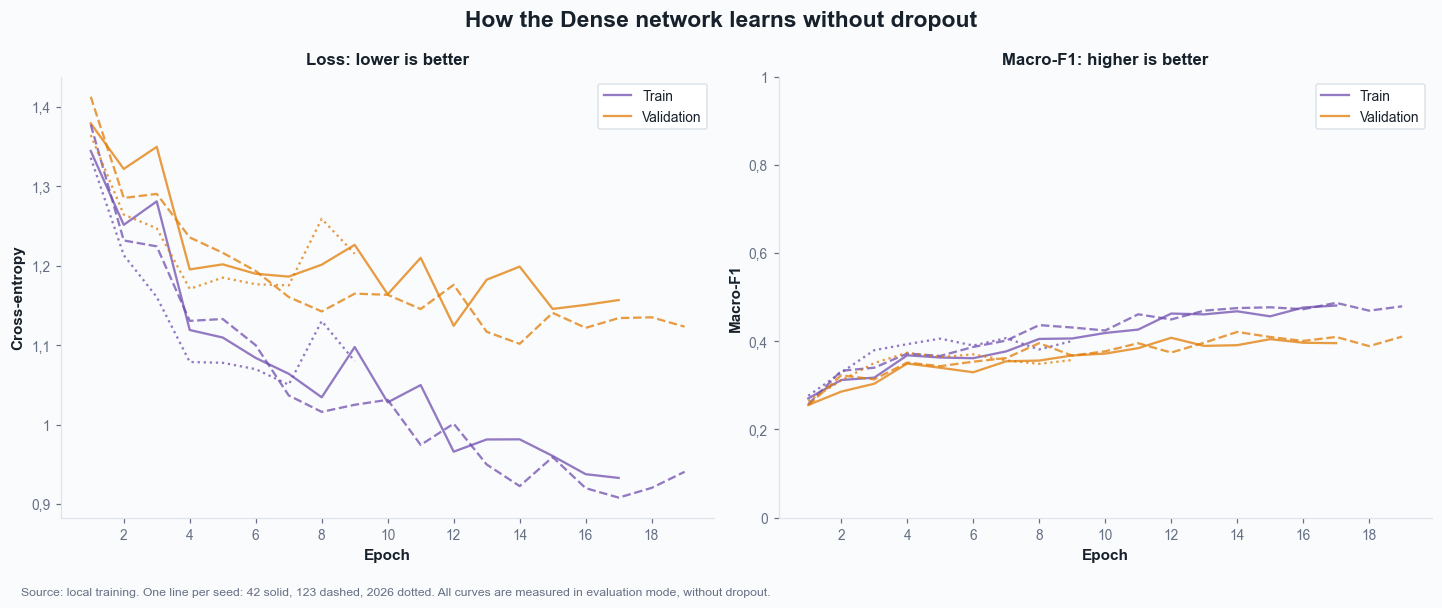

En los checkpoints baseline, macro-F1 medio de train = **0,444** y de validation = **0,401**; diferencia = **0,043**. Esta separación describe generalización en la muestra, no identifica por sí sola su causa.

In [10]:
show_compact(curves_figure(context, RESULTS), width=850)
baseline = records.loc[records.variant.eq('baseline')]
train_f1 = baseline.train_macro_f1.mean()
val_f1 = baseline.validation_macro_f1.mean()
display(Markdown(f"En los checkpoints baseline, macro-F1 medio de train = **{number(train_f1, 3)}** y de validation = **{number(val_f1, 3)}**; diferencia = **{number(train_f1-val_f1, 3)}**. Esta separación describe generalización en la muestra, no identifica por sí sola su causa."))

### Comprobar si ayuda dropout

Dropout apaga temporalmente una parte de las neuronas durante el entrenamiento. Con 0,30, la probabilidad de apagado es del 30 %. Al evaluar, deja de aplicarse.

La tabla compara las tres semillas de cada opción. **La media** resume el resultado y **la desviación típica** muestra cuánto cambia entre semillas. No elegimos solo la ejecución que mejor sale.

Después comparamos las dos opciones dentro de cada semilla. Una diferencia positiva favorece dropout; una negativa favorece la red sin dropout. La conclusión se limita a esta configuración.

Modelo,Macro-F1 medio,Desv. típica F1,Accuracy media,Desv. típica accuracy
Sin dropout,"0,401","0,024","0,653","0,017"
"Dropout 0,30","0,234","0,018","0,580","0,012"


Modelo,Semillas,Tiempo total (s)
Sin dropout,3,"688,256"
"Dropout 0,30",3,"1.280,453"


Semilla,Sin dropout,"Dropout 0,30",Diferencia de macro-F1
42,"0,408","0,254","-0,154"
123,"0,421","0,221","-0,201"
2026,"0,374","0,227","-0,147"


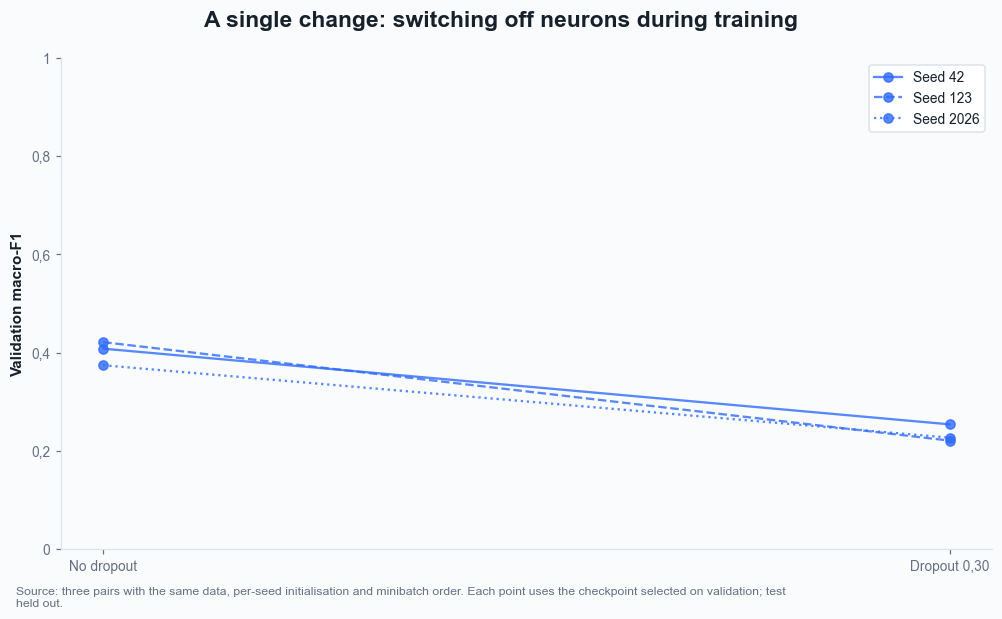

Dropout mejora en **0 de 3 semillas**; diferencia media = **-0,1674** de macro-F1, desviación típica = **0,0289**. La conclusión se limita a esta configuración, estas particiones y estas semillas; no demuestra que dropout ayude siempre.

In [11]:
aggregate = records.groupby('variant').agg(
    semillas=('seed', 'count'), macro_F1_media=('validation_macro_f1', 'mean'),
    macro_F1_std=('validation_macro_f1', 'std'), accuracy_media=('validation_accuracy', 'mean'),
    accuracy_std=('validation_accuracy', 'std'), tiempo_total_s=('train_seconds', 'sum'),
)
display_es(aggregate[['macro_F1_media','macro_F1_std','accuracy_media','accuracy_std']])
display_es(aggregate[['semillas','tiempo_total_s']])
paired = records.pivot(index='seed', columns='variant', values='validation_macro_f1')
paired['diferencia_dropout_menos_baseline'] = paired.dropout_030 - paired.baseline
display_es(paired)
show_compact(dropout_figure(context, records), width=760)
delta = paired['diferencia_dropout_menos_baseline']
positive = int((delta > 0).sum())
display(Markdown(f"Dropout mejora en **{positive} de 3 semillas**; diferencia media = **{number(delta.mean(), 4)}** de macro-F1, desviación típica = **{number(delta.std(), 4)}**. La conclusión se limita a esta configuración, estas particiones y estas semillas; no demuestra que dropout ayude siempre."))
aggregate.to_csv(RESULTS/'analysis_seed_summary.csv')
paired.to_csv(RESULTS/'analysis_dropout_pairs.csv')

## 9. Comparar con las referencias del 03

Comprobamos que las predicciones correspondan a las mismas imágenes de validation. Comparamos la Dense con predecir siempre la clase mayoritaria y con la regresión logística de color.

El **intervalo de confianza del 95 %** se calcula remuestreando productos completos: sus variantes permanecen juntas. Describe incertidumbre para esta validation y este modelo. No es una garantía sobre todo el catálogo ni recoge toda la variación entre entrenamientos.

La comparación con la logística cambia tanto los datos de entrada como el clasificador; una mejora no demuestra por sí sola qué parte del cambio la provoca.

In [12]:
from sklearn.metrics import confusion_matrix
predictions = pd.read_csv(RESULTS/'baseline_seed42_predictions.csv.gz', dtype={'article_id':'string', 'group_id':'string'})
assert predictions.article_id.tolist() == rows['validation'].article_id.tolist()
y = rows['validation'].label_id.astype(int).to_numpy()
pred = predictions.predicted_label_id.to_numpy()
classical_predictions = np.load(ROOT/'results/metrics/03_eda/validation_predictions.npz', allow_pickle=False)
assert classical_predictions['article_ids'].tolist() == predictions.article_id.tolist()
np.testing.assert_array_equal(classical_predictions['y'], y)
classical = pd.read_csv(ROOT/'results/metrics/03_eda/validation_baselines.csv').set_index('Modelo')
reference = baseline.loc[baseline.seed.eq(42)].iloc[0]
comparison = classical[['accuracy','macro_F1']].copy()
comparison.loc['Dense, semilla 42'] = [reference.validation_accuracy, reference.validation_macro_f1]
comparison.loc['Dense, media 3 semillas'] = [baseline.validation_accuracy.mean(), baseline.validation_macro_f1.mean()]
display_es(comparison)
ci = reference.validation_group_bootstrap_ci95_macro_f1
display(Markdown(f"Dense semilla 42: **macro-F1 {number(reference.validation_macro_f1, 3)}**, IC bootstrap por grupos 95 % **[{number(ci[0], 3)}, {number(ci[1], 3)}]**. No es un IC sobre toda la distribución del catálogo."))
paired_ci = grouped_intervals(y, pred, predictions.group_id, len(names), draws=300, seed=42,
                              other=classical_predictions['model_1'])
display(Markdown(f"Diferencia Dense42 − logística de color: **{number(reference.validation_macro_f1-classical.loc['Logística de color','macro_F1'], 3)}** de macro-F1; IC emparejado por grupos **[{number(paired_ci[0][1], 3)}, {number(paired_ci[1][1], 3)}]**. Este contraste cambia representación y clasificador, por lo que no aísla solo el efecto de las capas Dense."))
comparison.to_csv(RESULTS/'analysis_classical_comparison.csv')

Modelo,Accuracy,Macro-F1
Mayoría train,"0,154","0,011"
Logística de color,"0,218","0,051"
"Dense, semilla 42","0,660","0,408"
"Dense, media 3 semillas","0,653","0,401"


Dense semilla 42: **macro-F1 0,408**, IC bootstrap por grupos 95 % **[0,377, 0,429]**. No es un IC sobre toda la distribución del catálogo.

Diferencia Dense42 − logística de color: **0,357** de macro-F1; IC emparejado por grupos **[0,327, 0,378]**. Este contraste cambia representación y clasificador, por lo que no aísla solo el efecto de las capas Dense.

## 10. Ver qué clases reconoce y cuáles confunde

La tabla muestra precisión, recall, F1 y número de imágenes por clase. **Precisión** indica cuánto acierta cuando predice esa clase. **Recall** indica cuántos ejemplos reales de esa clase encuentra. **F1** combina ambas medidas.

En las matrices, **las filas son las clases reales y las columnas las predicciones**. La diagonal contiene los aciertos. Mostramos por separado los recuentos y la proporción dentro de cada clase para poder leer todas las etiquetas.

Usamos siempre la semilla 42 para ilustrar los errores; las otras semillas siguen incluidas en el resultado medio.

Clase,Precisión,Recall,F1,Imágenes
Blazer,"0,699","0,669","0,683",142
Blouse,"0,370","0,197","0,257",528
Bodysuit,"0,367","0,306","0,333",36
Cardigan,0,0,0,133
Coat,"0,469","0,259","0,333",58
Costumes,0,0,0,0
Dress,"0,765","0,922","0,836",1.156
Dungarees,"0,250","0,105","0,148",19
Garment Set,0,0,0,7
Hoodie,"0,689","0,360","0,473",228


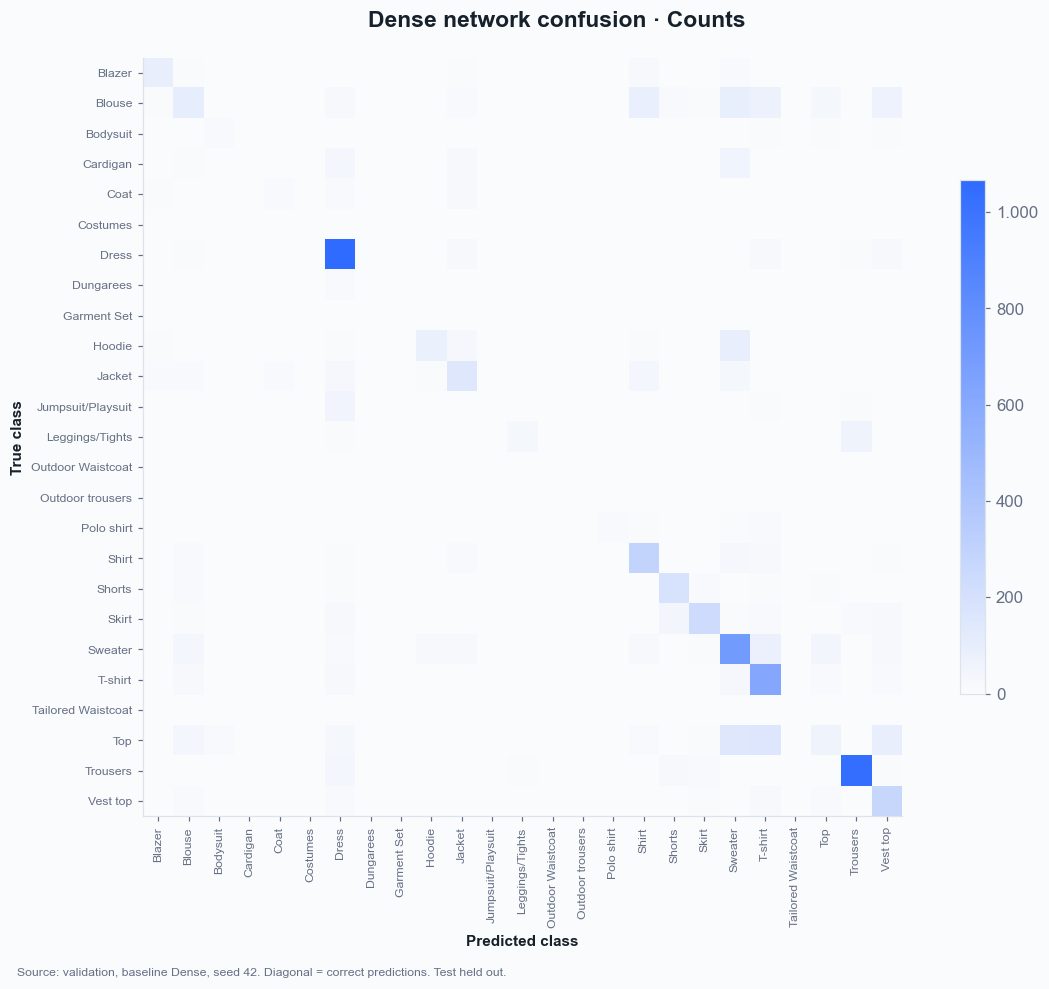

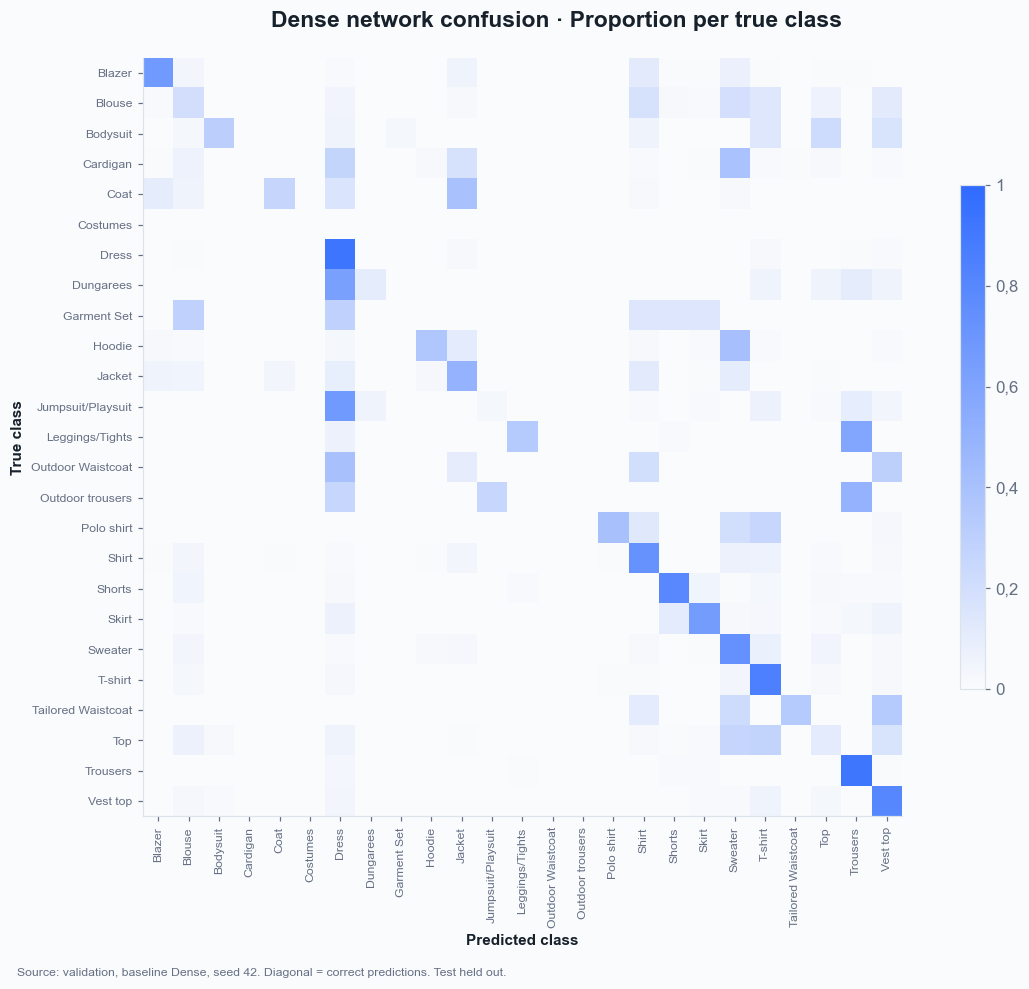

/var/folders/_y/rfcjxtgs1c1_w1dp22mxqjp40000gn/T/ipykernel_76390/501369199.py:9: RuntimeWarning: invalid value encountered in scalar divide
  'Proporción de la clase real':float(cm[i,j]/cm[i].sum())}


Real,Predicha,Errores,Fracción de la clase real
Top,T-shirt,150,"0,270"
Top,Sweater,145,"0,261"
Blouse,Sweater,99,"0,188"
Hoodie,Sweater,93,"0,408"
Top,Vest top,93,"0,168"
Blouse,Shirt,91,"0,172"
Sweater,T-shirt,75,"0,077"
Blouse,T-shirt,73,"0,138"


In [13]:
report = json.loads((RESULTS/'baseline_seed42_per_class.json').read_text(encoding='utf-8'))
per_class = pd.DataFrame({name: report[name] for name in names}).T
per_class.index.name = 'Clase'
display_es(per_class)
cm = confusion_matrix(y, pred, labels=np.arange(len(names)))
show_compact(confusion_figure(context, cm), width=900)
pairs = pd.DataFrame([
    {'Real':names[i], 'Predicha':names[j], 'Errores':int(cm[i,j]),
     'Proporción de la clase real':float(cm[i,j]/cm[i].sum())}
    for i in range(len(names)) for j in range(len(names)) if i != j
]).sort_values(['Errores','Real','Predicha'], ascending=[False,True,True])
display_es(pairs.head(8))
pairs.to_csv(RESULTS/'analysis_confusion_pairs.csv', index=False)

### Comparar el F1 de cada prenda

El gráfico enfrenta la Dense con la logística de color, clase por clase. Así vemos si la mejora global alcanza a todas las prendas o se concentra en unas pocas.

Un mal resultado no demuestra que la etiqueta esté equivocada. El fondo, el encuadre, las poses y el parecido entre prendas son posibles explicaciones que requieren revisión.

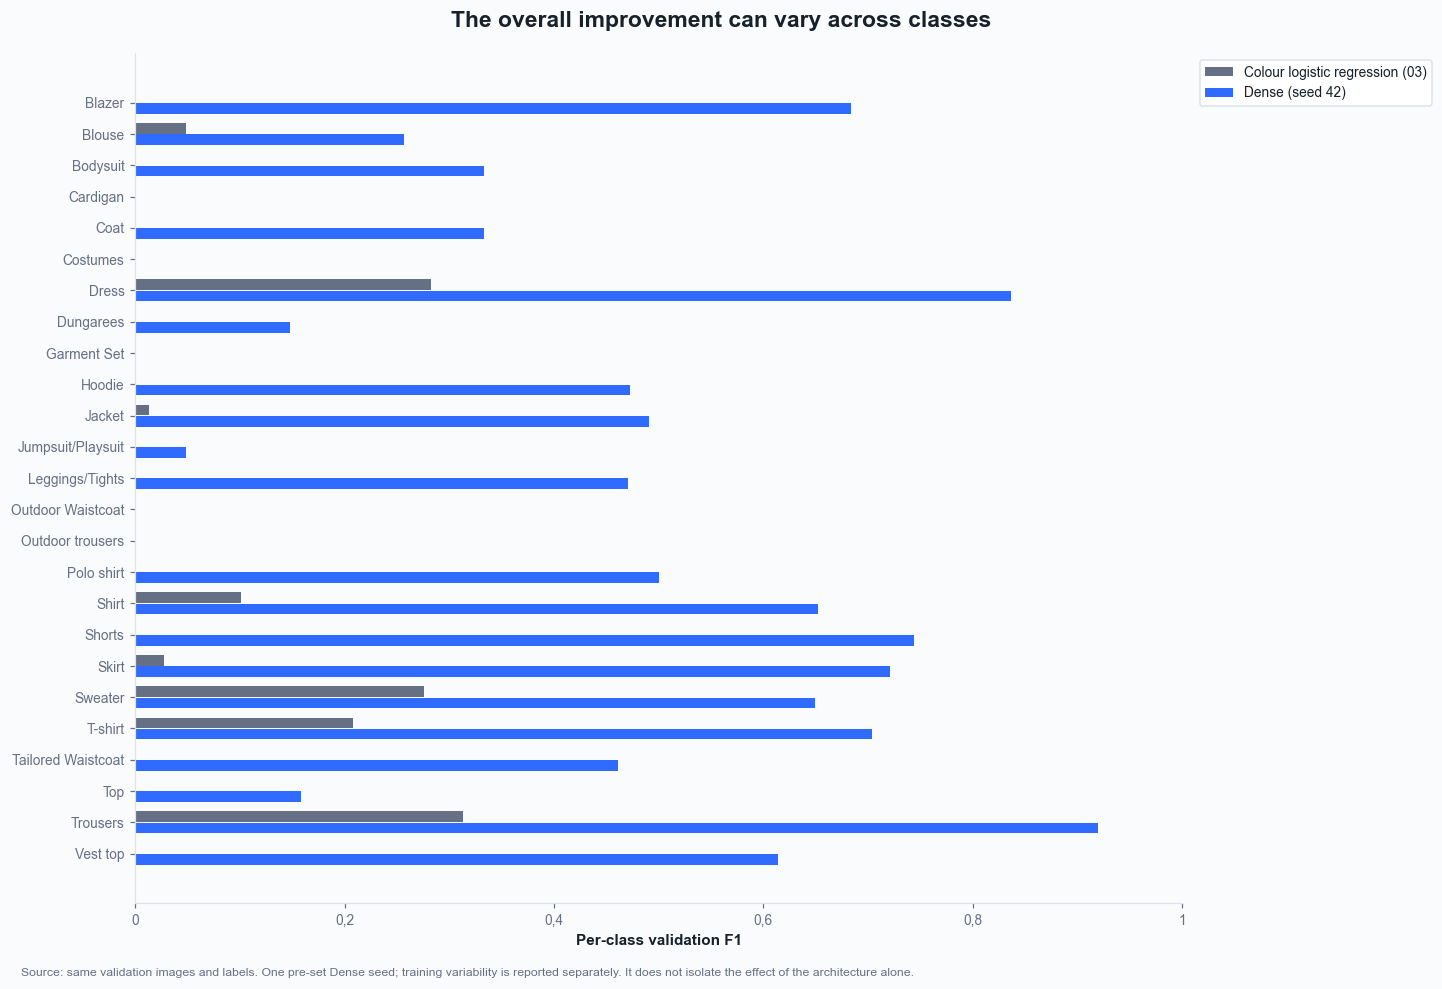

En esta ejecución, mayor F1: **Trousers (0,920)**; menor F1: **Cardigan (0,000)**. El error más frecuente en recuentos es **Top → T-shirt**, con **150 imágenes**. Son observaciones de validation, no propiedades universales de las categorías.

In [14]:
colour_report = pd.read_csv(ROOT/'results/metrics/03_eda/validation_colour_per_class.csv', index_col=0)
show_compact(per_class_figure(context, report, colour_report), width=900)
best_class = per_class['f1-score'].idxmax()
worst_class = per_class['f1-score'].idxmin()
most_confused = pairs.iloc[0]
display(Markdown(f"En esta ejecución, mayor F1: **{best_class} ({number(per_class.loc[best_class,'f1-score'], 3)})**; menor F1: **{worst_class} ({number(per_class.loc[worst_class,'f1-score'], 3)})**. El error más frecuente en recuentos es **{most_confused.Real} → {most_confused.Predicha}**, con **{number(most_confused.Errores)} imágenes**. Son observaciones de validation, no propiedades universales de las categorías."))

### Inspeccionar errores con confianza alta

Mostramos en miniatura los ocho errores con mayor softmax. **Una confianza alta no garantiza un acierto**: incluso un 100,0 % redondeado puede acompañar una predicción equivocada.

Son errores llamativos seleccionados automáticamente, no una muestra representativa. No corregimos las etiquetas basándonos solo en lo que predice la red.

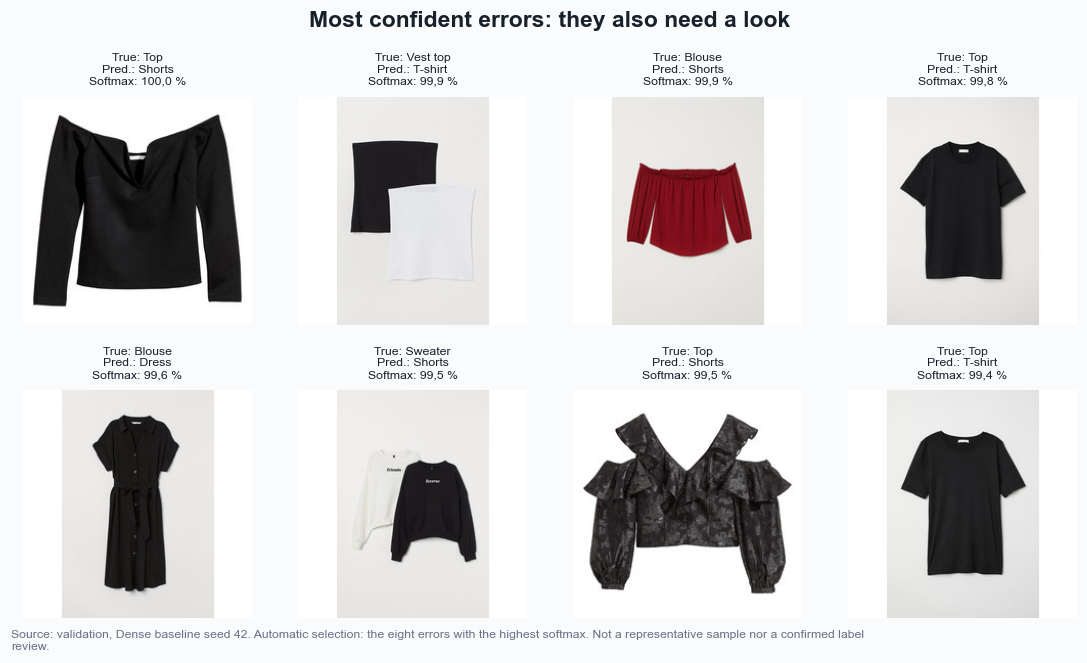

In [15]:
show_compact(errors_figure(context, predictions), width=720)

## 11. Observar pesos y activaciones

Reorganizamos los pesos de seis neuronas como cuadrículas de 64 × 64. **Son pesos del modelo, no fotografías ni explicaciones causales.** Usamos la misma escala para compararlos.

También medimos cuántas veces se activa cada neurona en una muestra fija de train. Que una neurona no se active en esa muestra no demuestra que sea inútil en todas las imágenes.

In [16]:
from pathlib import PureWindowsPath
# La ruta guardada puede venir de Windows (barras invertidas): se lee igual en macOS/Linux.
checkpoint = ROOT/PureWindowsPath(reference.checkpoint).as_posix()
if not checkpoint.is_file():
    # Los pesos no se suben a Git: sin ellos no se dibujan estas dos figuras ni se entrena nada.
    display(Markdown(f"**Pesos no disponibles en este equipo:** `{PureWindowsPath(reference.checkpoint).as_posix()}`. Las figuras de pesos y activaciones quedan pendientes; el resto de resultados no depende de ellos."))
else:
    assert sha256(checkpoint) == reference.checkpoint_sha256
    saved = torch.load(checkpoint, map_location='cpu', weights_only=True)
    model = model_from_config(config, dropout=0.0)
    model.load_state_dict(saved['state_dict'])
    model.eval()
    show_compact(weight_figure(context, model), width=720)
    show_compact(activation_figure(context, model, tensors), width=850)
    with torch.inference_mode():
        hidden = torch.relu(model.network[1](tensors['train'][:512].flatten(1)))
        inactive = int((hidden > 0).sum(0).eq(0).sum())
    display(Markdown(f"**{inactive} de 80 neuronas** no se activan en esta muestra de 512 imágenes. Es un diagnóstico de esta muestra y checkpoint; no demuestra que sean inútiles en cualquier entrada ni explica por sí solo el efecto del dropout."))

**Pesos no disponibles en este equipo:** `results/models/04_dense/143ad91452347fef/baseline_seed42.pt`. Las figuras de pesos y activaciones quedan pendientes; el resto de resultados no depende de ellos.

## 12. Leer el coste y comprobar la procedencia

La tabla muestra tiempo de entrenamiento, tiempo de inferencia y memoria del proceso. El entrenamiento incluye la evaluación por época; no incluye preparar las imágenes ni exportar figuras.

La inferencia se mide con entradas ya preparadas y batches de 32. No representa el tiempo completo de una aplicación que deba abrir un JPEG. La memoria incluye Python, librerías y datos, además de la red.

Guardamos la publicación de datos, las semillas, las versiones y los hashes para identificar qué produjo estos resultados. Repetir una semilla no garantiza el mismo resultado en otro hardware o con otras versiones.

In [17]:
cost = records[['variant','seed','parameters','approx_linear_flops_per_image',
                'train_seconds','inference_ms_per_image','peak_process_rss_bytes']].copy()
cost['RSS proceso (MiB)'] = cost.pop('peak_process_rss_bytes')/1024**2
display(Markdown(f'**Capacidad común:** {number(int(records.parameters.iloc[0]))} parámetros y {number(int(records.approx_linear_flops_per_image.iloc[0]))} FLOPs lineales aproximados por imagen.'))
display_es(cost.drop(columns=['parameters','approx_linear_flops_per_image']))
display(Markdown(f"**Coste total de las seis ejecuciones:** {number(records.train_seconds.sum()/60, 2)} minutos, más preparación y análisis. Hardware: `{summary['hardware']['processor']}`, CPU con {summary['hardware']['threads_used']} hilos."))
provenance = pd.DataFrame({
    'Elemento': ['Dataset', 'Configuración', 'Código de modelo', 'Código de entrenamiento', 'PyTorch', 'Checkpoint ilustrado'],
    'Referencia': [summary['dataset_run'], summary['identity']['sources']['config/dense_baseline_v1.json'],
                  summary['identity']['sources']['src/models/dense.py'],
                  summary['identity']['sources']['src/training/dense_experiment.py'],
                  summary['identity']['versions']['torch'], str(reference.checkpoint)],
})
display_es(provenance)
if checkpoint.is_file():
    assert parameter_count(model) == expected_parameters
    assert int(saved['epoch']) == int(reference.selected_epoch)
    display(Markdown('**Verificado:** seis ejecuciones terminadas, checkpoints reabiertos y reproducibles, IDs alineados con 03, cero fotografías ni predicciones de test. Pesos y cachés se conservan en local; métricas, figuras y salidas del notebook documentan el experimento.'))
else:
    display(Markdown('**Verificado sin pesos locales:** seis ejecuciones terminadas, resultados con hashes correctos, IDs alineados con 03, cero fotografías ni predicciones de test. El checkpoint no se ha podido reabrir en este equipo.'))

**Capacidad común:** 986.537 parámetros y 1.972.800 FLOPs lineales aproximados por imagen.

Modelo,Semilla,Entrenamiento (s),Inferencia (ms/imagen),RSS proceso (MiB)
Sin dropout,42,"261,653","0,109","2.966,551"
Sin dropout,123,"288,792","0,040","2.778,277"
Sin dropout,2026,"137,812","0,048","2.778,363"
"Dropout 0,30",42,"430,667","0,045","2.778,473"
"Dropout 0,30",123,"452,519","0,048","2.778,477"
"Dropout 0,30",2026,"397,268","0,044","2.453,133"


**Coste total de las seis ejecuciones:** 32,81 minutos, más preparación y análisis. Hardware: `Intel64 Family 6 Model 165 Stepping 2, GenuineIntel`, CPU con 4 hilos.

Elemento,Referencia
Dataset,20261125T152902-c912cdcc
Configuración,bc909ed09536f3a9cf3c31367bd312e17efe69e57335ccb1a6570bf805e34cd2
Código de modelo,688afb2e8be29544a134adb924545eec33f3b3d62f7ecf06061cc952b6d63c95
Código de entrenamiento,a8dd059fb11c373a4e1d9342ab7f1762e98a55355a6e108e8f81ca8fdcb5c102
PyTorch,2.7.1+cpu
Checkpoint ilustrado,results\models\04_dense\143ad91452347fef\baseline_seed42.pt


**Verificado sin pesos locales:** seis ejecuciones terminadas, resultados con hashes correctos, IDs alineados con 03, cero fotografías ni predicciones de test. El checkpoint no se ha podido reabrir en este equipo.

## 13. Recoger las conclusiones

Las cifras siguientes se calculan a partir de los resultados anteriores. Resumimos qué consigue la Dense, qué cambia con dropout y qué comparación queda pendiente. No rellenamos estas conclusiones con resultados supuestos.

In [18]:
logistic_f1 = classical.loc['Logística de color','macro_F1']
display(Markdown(f"""
- **Baseline neuronal:** macro-F1 medio de validation **{number(val_f1, 3)} ± {number(baseline.validation_macro_f1.std(), 3)}** entre tres semillas; accuracy media **{percent(baseline.validation_accuracy.mean())}**. El símbolo ± indica desviación típica entre semillas.
- **Respecto a 03:** la Dense42 obtiene **{number(reference.validation_macro_f1, 3)}** frente a **{number(logistic_f1, 3)}** de la logística de color. El contraste combina cambios de representación y clasificador.
- **Dropout 0,30:** diferencia media emparejada **{number(delta.mean(), 4)}** de macro-F1; mejora en **{positive}/3 semillas**. No extrapolamos a otras arquitecturas ni a otros valores de dropout.
- **Generalización:** separación media train − validation de **{number(train_f1-val_f1, 3)}** en macro-F1 para el baseline. Debe leerse junto a las curvas y los errores, no como una explicación causal aislada.
- **Siguiente paso:** notebook 05, CNN RGB64 con presupuesto de parámetros comparable y las mismas particiones. Hasta entonces **H1 no está resuelta**.
"""))


- **Baseline neuronal:** macro-F1 medio de validation **0,401 ± 0,024** entre tres semillas; accuracy media **65,3 %**. El símbolo ± indica desviación típica entre semillas.
- **Respecto a 03:** la Dense42 obtiene **0,408** frente a **0,051** de la logística de color. El contraste combina cambios de representación y clasificador.
- **Dropout 0,30:** diferencia media emparejada **-0,1674** de macro-F1; mejora en **0/3 semillas**. No extrapolamos a otras arquitecturas ni a otros valores de dropout.
- **Generalización:** separación media train − validation de **0,043** en macro-F1 para el baseline. Debe leerse junto a las curvas y los errores, no como una explicación causal aislada.
- **Siguiente paso:** notebook 05, CNN RGB64 con presupuesto de parámetros comparable y las mismas particiones. Hasta entonces **H1 no está resuelta**.


### Límites y conexión con el informe

Estos resultados son de validation, que también usamos para elegir la época. El resultado final de test sigue pendiente. Las clases conservadas delimitan nuestro problema; no representan todo el catálogo ni otras marcas.

Si las fotos se han filtrado con CLIP en 02, hay que declararlo: la selección utiliza un modelo preentrenado, aunque esta Dense aprenda desde cero. Todas las arquitecturas comparadas deben recibir los mismos conjuntos filtrados de train, validation y test. La evaluación describe este conjunto filtrado, no la mezcla anterior de fotos.

El resumen inicial del informe tiene un máximo de tres páginas según el profesor. Podemos recoger el objetivo, el método, los resultados principales, sus limitaciones y el siguiente paso. El detalle de las seis ejecuciones puede quedar aquí o en un anexo.

Referencias: [entropía cruzada](https://docs.pytorch.org/docs/2.7/generated/torch.nn.CrossEntropyLoss.html) y [reproducibilidad en PyTorch](https://docs.pytorch.org/docs/2.7/notes/randomness.html). Las decisiones de tamaños, presupuesto y comparación son del proyecto; no se presentan como instrucciones literales del profesor.